In [ ]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from MyTree import MyDecisionTree


In [15]:
data = load_wine()


In [16]:
X = data.data
y = data.target

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
my_tree = MyDecisionTree(max_depth=5)

In [19]:
my_tree.fit(X_train, y_train)

In [20]:
pred_my = my_tree.predict(X_test)

In [27]:
acc_my = accuracy_score(y_test, pred_my)
acc_my 

0.9166666666666666

In [22]:
sk_tree = DecisionTreeClassifier(max_depth=5)

In [23]:
sk_tree.fit(X_train, y_train)
pred_sk = sk_tree.predict(X_test)


In [26]:
acc_sk = accuracy_score(y_test, pred_sk)
acc_sk 

0.9444444444444444

In [25]:
import matplotlib.pyplot as plt

In [28]:
models = ["My Decision Tree", "Sklearn Decision Tree"]
scores = [acc_my, acc_sk]

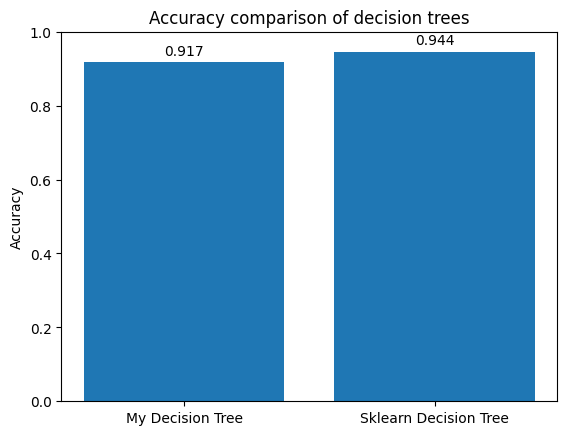

In [29]:
plt.figure()
plt.bar(models, scores)

plt.title("Accuracy comparison of decision trees")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, v in enumerate(scores):
    plt.text(i, v + 0.02, str(round(v, 3)), ha='center')

plt.show()

In [37]:
import numpy as np
from sklearn.datasets import make_classification

In [38]:
X, y = make_classification(
    n_samples=300, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, n_classes=3, random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [41]:
my_tree = MyDecisionTree(max_depth=5)
my_tree.fit(X_train, y_train)

# sklearn дерево
sk_tree = DecisionTreeClassifier(max_depth=5)
sk_tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [42]:
def plot_decision_boundary(X, y, model, title):
    # создаём сетку
    x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1
    y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    # предсказания модели на сетке
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # цветная заливка областей
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X[:,0], X[:,1], c=y, edgecolor='k', cmap=plt.cm.coolwarm)
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

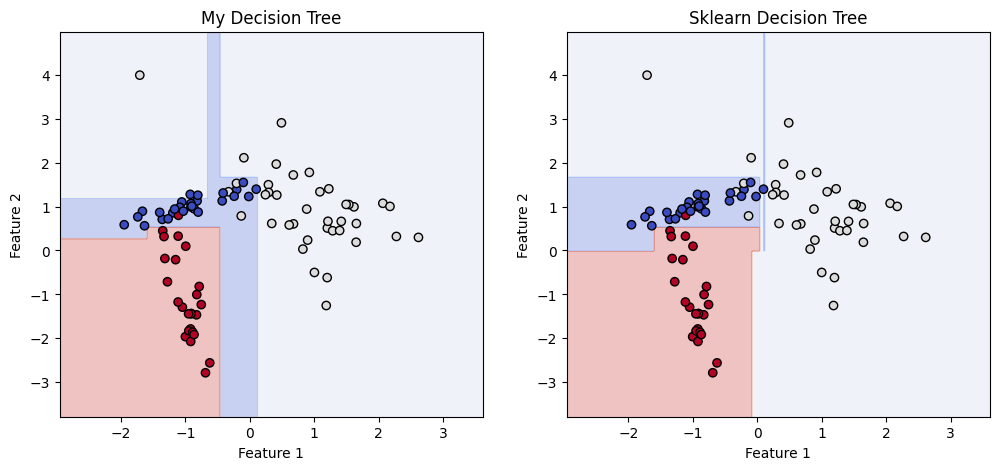

In [43]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plot_decision_boundary(X_test, y_test, my_tree, "My Decision Tree")

plt.subplot(1,2,2)
plot_decision_boundary(X_test, y_test, sk_tree, "Sklearn Decision Tree")

plt.show()